Total Weeks Modeled: 209 (2015-01-04 to 2018-12-30)

--- PATH 1: NORMAL 4-WEEK MOVING AVERAGE ---
Mean Absolute Error (MAE): EUR 5,780.67 | MAPE: 46.5%

--- PATH 2: GRADIENT BOOSTING REGRESSOR ---
Mean Absolute Error (MAE): EUR 5,401.21 | MAPE: 33.1%
Forecast Error Reduction vs. Moving Average: +6.6%



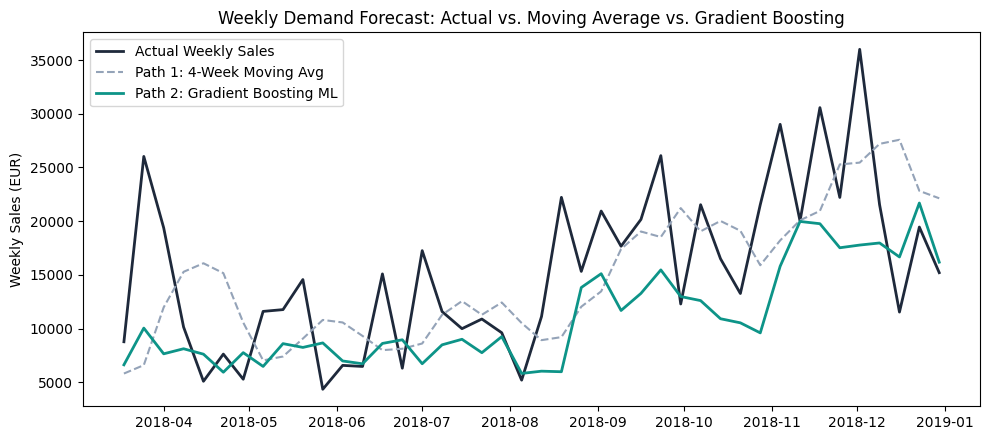

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error

# 1. Load & Aggregate Daily Orders into Weekly Demand
sales = pd.read_csv('superstore_sales.csv')
sales['Order Date'] = pd.to_datetime(sales['Order Date'], dayfirst=True, format='mixed')

weekly = sales.set_index('Order Date').resample('W')['Sales'].sum().reset_index()
weekly = weekly.sort_values('Order Date').reset_index(drop=True)

# 2. Time-Series Feature Engineering (Strict No-Leakage Lags)
weekly['Week_Num'] = np.arange(len(weekly))
weekly['Month'] = weekly['Order Date'].dt.month
weekly['Quarter'] = weekly['Order Date'].dt.quarter
weekly['Week_of_Year'] = weekly['Order Date'].dt.isocalendar().week.astype(int)
weekly['Lag_1W'] = weekly['Sales'].shift(1).bfill()
weekly['Lag_4W'] = weekly['Sales'].shift(4).bfill()
weekly['Rolling_4W'] = weekly['Sales'].shift(1).rolling(4).mean().bfill()

print(f"Total Weeks Modeled: {len(weekly)} ({weekly['Order Date'].min().date()} to {weekly['Order Date'].max().date()})\n")

# 3. Chronological Train / Test Split (First 80% Train, Final 20% Holdout Test)
split = int(len(weekly) * 0.80)
train, test = weekly.iloc[:split].copy(), weekly.iloc[split:].copy()

# ==========================================================
# PATH 1: NORMAL SQL / EXCEL BASELINE (4-Week Moving Average)
# ==========================================================
mae_rule = mean_absolute_error(test['Sales'], test['Rolling_4W'])
mape_rule = mean_absolute_percentage_error(test['Sales'], test['Rolling_4W'])

print("--- PATH 1: NORMAL 4-WEEK MOVING AVERAGE ---")
print(f"Mean Absolute Error (MAE): EUR {mae_rule:,.2f} | MAPE: {mape_rule:.1%}\n")

# ==========================================================
# PATH 2: MACHINE LEARNING UPGRADE (GRADIENT BOOSTING)
# ==========================================================
feats = ['Week_Num', 'Month', 'Quarter', 'Week_of_Year', 'Lag_1W', 'Lag_4W', 'Rolling_4W']
gbr = GradientBoostingRegressor(n_estimators=200, max_depth=4, learning_rate=0.05, random_state=42)
gbr.fit(train[feats], train['Sales'])

test['ML_Forecast'] = gbr.predict(test[feats]).round(2)
test['Rolling_4W'] = test['Rolling_4W'].round(2)

mae_ml = mean_absolute_error(test['Sales'], test['ML_Forecast'])
mape_ml = mean_absolute_percentage_error(test['Sales'], test['ML_Forecast'])
error_reduction = (mae_rule - mae_ml) / mae_rule

print("--- PATH 2: GRADIENT BOOSTING REGRESSOR ---")
print(f"Mean Absolute Error (MAE): EUR {mae_ml:,.2f} | MAPE: {mape_ml:.1%}")
print(f"Forecast Error Reduction vs. Moving Average: {error_reduction:+.1%}\n")

# 4. Export Forecast Table & Visual Comparison Chart
test[['Order Date', 'Sales', 'Rolling_4W', 'ML_Forecast']].to_csv('Weekly_Demand_Forecast.csv', index=False)

plt.figure(figsize=(10, 4.5))
plt.plot(test['Order Date'], test['Sales'], label='Actual Weekly Sales', color='#1E293B', linewidth=2)
plt.plot(test['Order Date'], test['Rolling_4W'], label='Path 1: 4-Week Moving Avg', linestyle='--', color='#94A3B8')
plt.plot(test['Order Date'], test['ML_Forecast'], label='Path 2: Gradient Boosting ML', color='#0D9488', linewidth=2)
plt.title('Weekly Demand Forecast: Actual vs. Moving Average vs. Gradient Boosting')
plt.ylabel('Weekly Sales (EUR)')
plt.legend()
plt.tight_layout()
plt.savefig('demand_forecast_chart.png', dpi=300)
plt.show()